# Ford GoBike Trip Data Analysis

**Data Science Module – AMIT Learning**

**Prepared by:** Farouk Mohamed

## Introduction

This project aims to analyze the Ford GoBike trip dataset to explore bike-sharing usage patterns and understand

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
df = pd.read_csv("fordgobike-tripdataFor201902.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())



Dataset loaded successfully!
Dataset shape: (183416, 16)


,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,52185,32:10.1,01:56.0,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,-122.402923,4902,Customer,1984.0,Male,No
1,42521,53:21.8,42:03.1,23.0,The Embarcadero at Steuart St,37.791464,-122.391034,81.0,Berry St at 4th St,37.775880,-122.393170,2535,Customer,NaN,NaN,No
2,61854,13:13.2,24:08.1,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,-122.404904,5905,Customer,1972.0,Male,No
3,36490,54:26.0,02:36.8,375.0,Grove St at Masonic Ave,37.774836,-122.446546,70.0,Central Ave at Fell St,37.773311,-122.444293,6638,Subscriber,1989.0,Other,No
4,1585,54:18.5,20:44.1,7.0,Frank H Ogawa Plaza,37.804562,-122.271738,222.0,10th Ave at E 15th St,37.792714,-122.248780,4898,Subscriber,1974.0,Male,Yes


In [31]:
pip install plotly


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



2. Data Gathering and Assessment

  Dataset Overview

In this section, we will explore the dataset structure, examine data types, review descriptive statistics, and identify missing values and duplicate records.


In [32]:
print("Number of rows", df.shape[0])
print("Number of columns", df.shape[1])

Number of rows 183416
Number of columns 16


In [33]:
print("data type")
df.info()

data type
<class 'pandas.DataFrame'>
RangeIndex: 183416 entries, 0 to 183415
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   duration_sec             183416 non-null  int64  
 1   start_time               183416 non-null  str    
 2   end_time                 183416 non-null  str    
 3   start_station_id         183219 non-null  float64
 4   start_station_name       183219 non-null  str    
 5   start_station_latitude   183416 non-null  float64
 6   start_station_longitude  183416 non-null  float64
 7   end_station_id           183219 non-null  float64
 8   end_station_name         183219 non-null  str    
 9   end_station_latitude     183416 non-null  float64
 10  end_station_longitude    183416 non-null  float64
 11  bike_id                  183416 non-null  int64  
 12  user_type                183416 non-null  str    
 13  member_birth_year        175151 non-null  float64
 14  membe

In [34]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
duration_sec,183416.0,726.067311,1794.371831,61.000000,325.000000,514.000000,796.000000,85444.000000
start_station_id,183219.0,138.590365,111.778938,3.000000,47.000000,104.000000,239.000000,398.000000
start_station_latitude,183416.0,37.771221,0.099586,37.317298,37.770083,37.780760,37.797280,37.880222
start_station_longitude,183416.0,-122.352661,0.117100,-122.453705,-122.412408,-122.398285,-122.286533,-121.874119
end_station_id,183219.0,136.249401,111.514916,3.000000,44.000000,100.000000,235.000000,398.000000
end_station_latitude,183416.0,37.771425,0.099494,37.317298,37.770407,37.781010,37.797320,37.880222
end_station_longitude,183416.0,-122.352247,0.116677,-122.453705,-122.411726,-122.398279,-122.288045,-121.874119
bike_id,183416.0,4472.890260,1664.386068,11.000000,3777.000000,4958.000000,5502.000000,6645.000000
member_birth_year,175151.0,1984.806504,10.116589,1878.000000,1980.000000,1987.000000,1992.000000,2001.000000


In [35]:

df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
duration_sec,183416.0,NaN,NaN,NaN,726.067311,1794.371831,61.0,325.0,514.0,796.0,85444.0
start_time,183416,35783,12:19.2,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_time,183416,35767,22:24.4,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_station_id,183219.0,NaN,NaN,NaN,138.590365,111.778938,3.0,47.0,104.0,239.0,398.0
start_station_name,183219,329,Market St at 10th St,3904,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_station_latitude,183416.0,NaN,NaN,NaN,37.771221,0.099586,37.317298,37.770083,37.78076,37.79728,37.880222
start_station_longitude,183416.0,NaN,NaN,NaN,-122.352661,0.1171,-122.453705,-122.412408,-122.398285,-122.286533,-121.874119
end_station_id,183219.0,NaN,NaN,NaN,136.249401,111.514916,3.0,44.0,100.0,235.0,398.0
end_station_name,183219,329,San Francisco Caltrain Station 2 (Townsend St...,4857,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_station_latitude,183416.0,NaN,NaN,NaN,37.771425,0.099494,37.317298,37.770407,37.78101,37.79732,37.880222


In [36]:

df.dtypes


duration_sec                 int64
start_time                     str
end_time                       str
start_station_id           float64
start_station_name             str
start_station_latitude     float64
start_station_longitude    float64
end_station_id             float64
end_station_name               str
end_station_latitude       float64
end_station_longitude      float64
bike_id                      int64
user_type                      str
member_birth_year          float64
member_gender                  str
bike_share_for_all_trip        str
dtype: object

In [37]:
df.dtypes.value_counts()

str        7
float64    7
int64      2
Name: count, dtype: int64

In [38]:
missing_values = df.isnull().sum()
missing_values

duration_sec                  0
start_time                    0
end_time                      0
start_station_id            197
start_station_name          197
start_station_latitude        0
start_station_longitude       0
end_station_id              197
end_station_name            197
end_station_latitude          0
end_station_longitude         0
bike_id                       0
user_type                     0
member_birth_year          8265
member_gender              8265
bike_share_for_all_trip       0
dtype: int64

In [39]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage *1


duration_sec               0.000000
start_time                 0.000000
end_time                   0.000000
start_station_id           0.107406
start_station_name         0.107406
start_station_latitude     0.000000
start_station_longitude    0.000000
end_station_id             0.107406
end_station_name           0.107406
end_station_latitude       0.000000
end_station_longitude      0.000000
bike_id                    0.000000
user_type                  0.000000
member_birth_year          4.506150
member_gender              4.506150
bike_share_for_all_trip    0.000000
dtype: float64

In [40]:

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 4


In [41]:

df.nunique()


duration_sec                4752
start_time                 35783
end_time                   35767
start_station_id             329
start_station_name           329
start_station_latitude       334
start_station_longitude      335
end_station_id               329
end_station_name             329
end_station_latitude         335
end_station_longitude        335
bike_id                     4646
user_type                      2
member_birth_year             75
member_gender                  3
bike_share_for_all_trip        2
dtype: int64

Data Cleaning

handle data type

In [45]:
df.dtypes

duration_sec                 int64
start_time                     str
end_time                       str
start_station_id           float64
start_station_name             str
start_station_latitude     float64
start_station_longitude    float64
end_station_id             float64
end_station_name               str
end_station_latitude       float64
end_station_longitude      float64
bike_id                      int64
user_type                      str
member_birth_year          float64
member_gender                  str
bike_share_for_all_trip        str
dtype: object

In [46]:
df["start_time"] = pd.to_datetime(df["start_time"], errors="coerce")
df["end_time"] = pd.to_datetime(df["end_time"], errors="coerce")
df[["start_time", "end_time"]].dtypes

C:\Users\hp\AppData\Local\Temp\ipykernel_5236\2672407533.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["start_time"] = pd.to_datetime(df["start_time"], errors="coerce")
C:\Users\hp\AppData\Local\Temp\ipykernel_5236\2672407533.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["end_time"] = pd.to_datetime(df["end_time"], errors="coerce")


start_time    datetime64[us]
end_time      datetime64[us]
dtype: object

In [47]:
df[["start_station_id", "end_station_id", "member_birth_year"]].isnull().sum()

start_station_id      197
end_station_id        197
member_birth_year    8265
dtype: int64

In [48]:
cat_cols = [
    "user_type",
    "member_gender",
    "bike_share_for_all_trip"
]

for col in cat_cols:
    df[col] = df[col].astype("category")

In [50]:
df["duration_min"] = df["duration_sec"] / 60
df[["duration_sec", "duration_min"]].head()

,duration_sec,duration_min
0,52185,869.750000
1,42521,708.683333
2,61854,1030.900000
3,36490,608.166667
4,1585,26.416667


handle NULLS

In [53]:
missing_count = df.isnull().sum()
print(missing_count )
print("*******************")
print(missing_count[missing_count > 0])

duration_sec                    0
start_time                 109501
end_time                   110151
start_station_id              197
start_station_name            197
start_station_latitude          0
start_station_longitude         0
end_station_id                197
end_station_name              197
end_station_latitude            0
end_station_longitude           0
bike_id                         0
user_type                       0
member_birth_year            8265
member_gender                8265
bike_share_for_all_trip         0
duration_min                    0
dtype: int64
*******************
start_time            109501
end_time              110151
start_station_id         197
start_station_name       197
end_station_id           197
end_station_name         197
member_birth_year       8265
member_gender           8265
dtype: int64


In [55]:
print("Missing values percentage:")
(df.isnull().sum() / len(df)) * 100

Missing values percentage:


duration_sec                0.000000
start_time                 59.700899
end_time                   60.055284
start_station_id            0.107406
start_station_name          0.107406
start_station_latitude      0.000000
start_station_longitude     0.000000
end_station_id              0.107406
end_station_name            0.107406
end_station_latitude        0.000000
end_station_longitude       0.000000
bike_id                     0.000000
user_type                   0.000000
member_birth_year           4.506150
member_gender               4.506150
bike_share_for_all_trip     0.000000
duration_min                0.000000
dtype: float64

In [56]:
print(df["start_time"].isnull().sum())
print(df["end_time"].isnull().sum())

109501
110151


In [57]:
df = df.dropna(subset=["start_time", "end_time"])

In [58]:
print(df[["start_time", "end_time"]].isnull().sum())
print(df.shape)

start_time    0
end_time      0
dtype: int64
(43853, 17)


Handle Duplicate

In [59]:
df.duplicated().sum()

np.int64(4)

In [66]:
df[df.duplicated(keep=False)]

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip,duration_min


In [64]:
print(" duplicate rows:")
df = df.drop_duplicates()

 duplicate rows:


In [65]:
print("Duplicates:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicates: 0
Dataset shape: (43849, 17)


Handle outliers

In [68]:
num_cols = ["duration_min", "member_birth_year"]

for col in num_cols:
    data = df[col]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_fence) | (data > upper_fence)
    ]

    print(f"\n{col}")
    print("Lower fence:", lower_fence)
    print("Upper fence:", upper_fence)
    print("Outliers count:", len(outliers))


duration_min
Lower fence: -3.666666666666665
Upper fence: 18.066666666666663
Outliers count: 1295

member_birth_year
Lower fence: 1962.0
Upper fence: 2010.0
Outliers count: 1243


In [69]:
df.loc[
    (df["duration_min"] > upper_fence),
    "duration_min"
].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: duration_min, dtype: float64

In [70]:
Q1 = df["duration_min"].quantile(0.25)
Q3 = df["duration_min"].quantile(0.75)

IQR = Q3 - Q1
upper_fence = Q3 + 1.5 * IQR

outliers = df.loc[
    df["duration_min"] > upper_fence,
    "duration_min"
]

print("Upper fence:", upper_fence)
print("Outliers count:", len(outliers))
print(outliers.describe())

Upper fence: 18.066666666666663
Outliers count: 1295
count    1295.000000
mean       64.091802
std       121.855928
min        18.066667
25%        19.583333
50%        39.550000
75%        57.525000
max      1373.083333
Name: duration_min, dtype: float64


In [71]:
df.nlargest(10, "duration_min")[["duration_min", "duration_sec"]]

,duration_min,duration_sec
173365,1373.083333,82385
145977,1191.166667,71470
75396,1133.816667,68029
7268,1101.083333,66065
129746,1066.950000,64017
136270,967.666667,58060
82862,960.700000,57642
138857,950.983333,57059
164944,947.866667,56872
81797,903.816667,54229


In [74]:
df.nlargest(10, "duration_min")[["duration_min", "duration_sec"]].to_string(index=False)

' duration_min  duration_sec\n  1373.083333         82385\n  1191.166667         71470\n  1133.816667         68029\n  1101.083333         66065\n  1066.950000         64017\n   967.666667         58060\n   960.700000         57642\n   950.983333         57059\n   947.866667         56872\n   903.816667         54229'

In [75]:
num_cols = ["duration_min"]

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    lower_outliers = df.loc[df[col] < lower_fence, col].values
    upper_outliers = df.loc[df[col] > upper_fence, col].values

    df[col] = df[col].replace(lower_outliers, lower_fence)
    df[col] = df[col].replace(upper_outliers, upper_fence)

In [76]:
print(df["member_birth_year"].describe())

count    42114.000000
mean      1984.977965
std         10.010475
min       1900.000000
25%       1980.000000
50%       1987.000000
75%       1992.000000
max       2001.000000
Name: member_birth_year, dtype: float64


In [77]:
print("Oldest birth year:")
print(df["member_birth_year"].nsmallest(10))

print("Newest birth year:")
print(df["member_birth_year"].nlargest(10))

Oldest birth year:
19375     1900.0
21506     1900.0
32942     1900.0
58222     1900.0
60960     1900.0
94616     1900.0
110468    1900.0
119010    1900.0
162051    1900.0
171757    1900.0
Name: member_birth_year, dtype: float64
Newest birth year:
157448    2001.0
157450    2001.0
157451    2001.0
157452    2001.0
179375    2001.0
2304      2000.0
2468      2000.0
3585      2000.0
3693      2000.0
4370      2000.0
Name: member_birth_year, dtype: float64


In [78]:
Q1 = df["member_birth_year"].quantile(0.25)
Q3 = df["member_birth_year"].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

print("Lower outliers:")
print(df.loc[df["member_birth_year"] < lower_fence, "member_birth_year"].value_counts().sort_index())

print("Upper outliers:")
print(df.loc[df["member_birth_year"] > upper_fence, "member_birth_year"].value_counts().sort_index())

Lower fence: 1962.0
Upper fence: 2010.0
Lower outliers:
member_birth_year
1900.0     10
1901.0      1
1902.0      1
1931.0     31
1933.0      1
1939.0      1
1941.0      1
1942.0     11
1943.0      7
1944.0      1
1945.0     29
1946.0      3
1947.0     25
1948.0      9
1949.0     17
1950.0     45
1951.0     32
1952.0     25
1953.0     39
1954.0     70
1955.0     27
1956.0     83
1957.0    153
1958.0    124
1959.0    129
1960.0    164
1961.0    204
Name: count, dtype: int64
Upper outliers:
Series([], Name: count, dtype: int64)


In [79]:
col = "member_birth_year"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

lower_outliers = df.loc[df[col] < lower_fence, col].values
upper_outliers = df.loc[df[col] > upper_fence, col].values

df[col] = df[col].replace(lower_outliers, lower_fence)
df[col] = df[col].replace(upper_outliers, upper_fence)

In [81]:
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    print(f"{col}:")
    print("Lower outliers:", (df[col] < lower_fence).sum())
    print("Upper outliers:", (df[col] > upper_fence).sum())

member_birth_year:
Lower outliers: 0
Upper outliers: 0


data vizuazlizatio Num

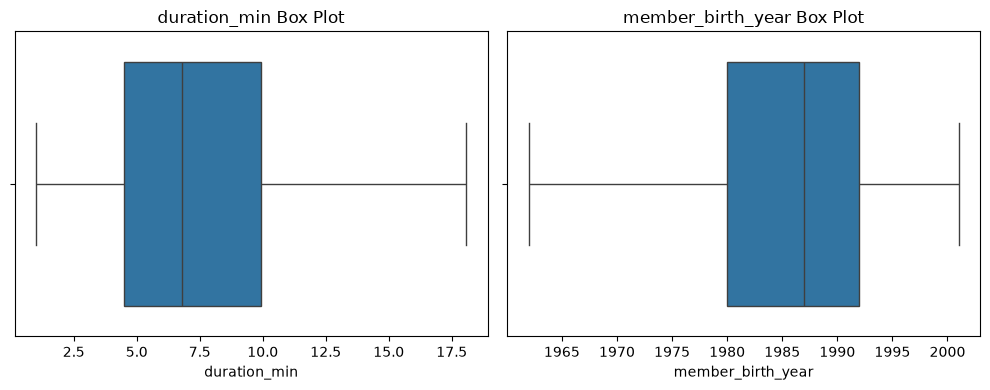

In [82]:
num_cols = ["duration_min", "member_birth_year"]

plt.figure(figsize=(10, 4))

for i, col in enumerate(num_cols):
    plt.subplot(1, len(num_cols), i + 1)
    sns.boxplot(x=df[col])
    plt.title(f"{col} Box Plot")

plt.tight_layout()
plt.show()

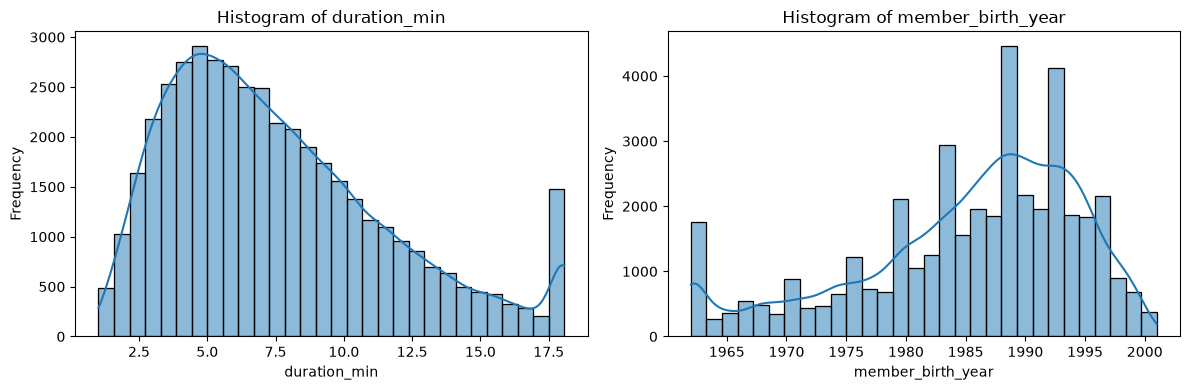

In [83]:
num_cols = ["duration_min", "member_birth_year"]

plt.figure(figsize=(12, 4))

for i, col in enumerate(num_cols):
    plt.subplot(1, len(num_cols), i + 1)

    sns.histplot(data=df, x=col, bins=30, kde=True)

    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

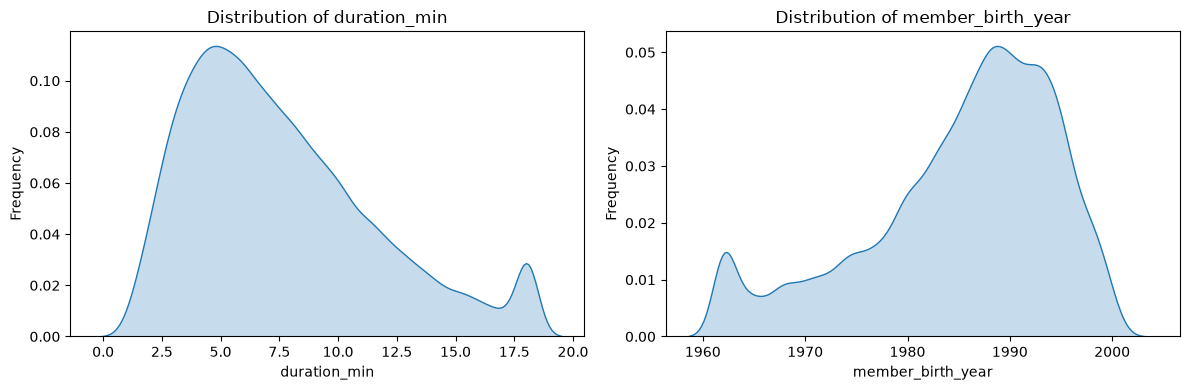

In [84]:
num_cols = ["duration_min", "member_birth_year"]

plt.figure(figsize=(12, 4))

for i, col in enumerate(num_cols):
    plt.subplot(1, len(num_cols), i + 1)

    sns.kdeplot(data=df, x=col, fill=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

data vizuazlizatio cat

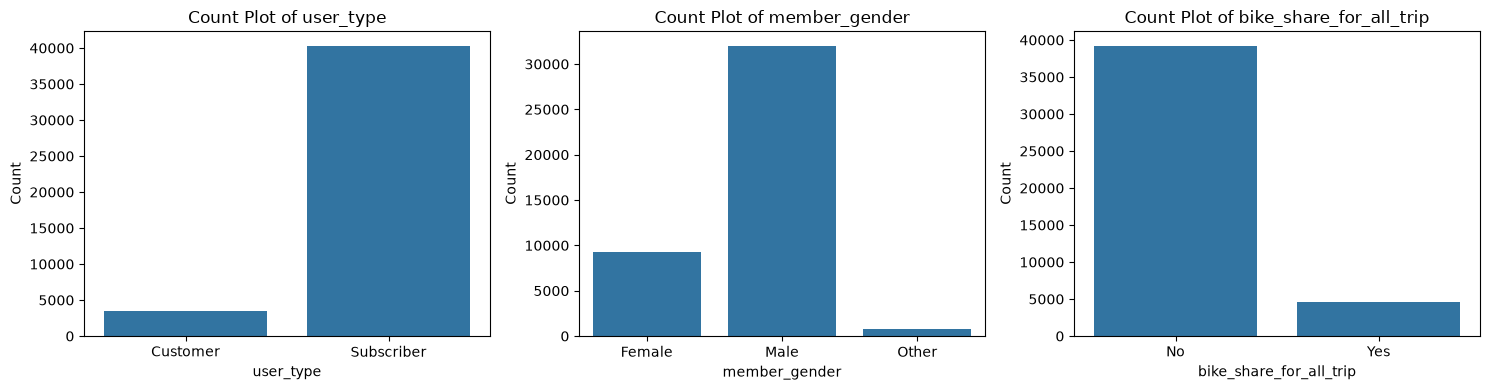

In [89]:
cat_cols = ["user_type", "member_gender", "bike_share_for_all_trip"]

plt.figure(figsize=(15, 4))

for i, col in enumerate(cat_cols):
    plt.subplot(1, len(cat_cols), i + 1)

    sns.countplot(data=df, x=col)

    plt.title(f"Count Plot of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
  

plt.tight_layout()
plt.show()

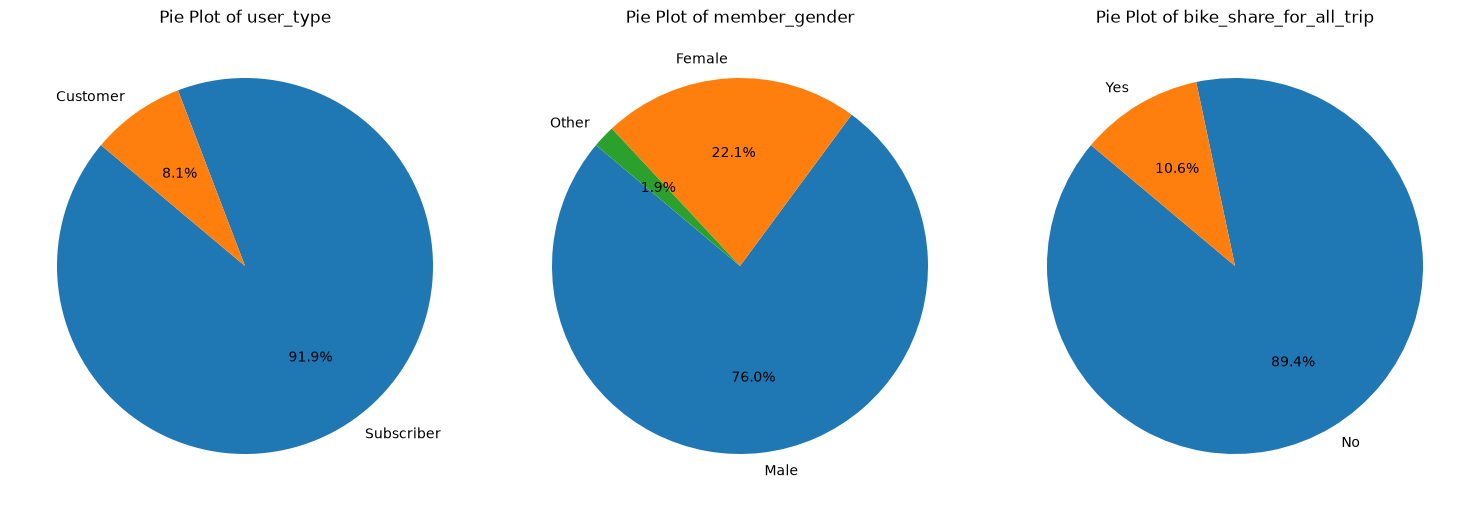

In [90]:
cat_cols = ["user_type", "member_gender", "bike_share_for_all_trip"]

plt.figure(figsize=(15, 5))

for i, col in enumerate(cat_cols):
    plt.subplot(1, len(cat_cols), i + 1)

    counts = df[col].value_counts()

    plt.pie(
        counts.values,
        labels=counts.index,
        autopct="%1.1f%%",
        startangle=140
    )

    plt.title(f"Pie Plot of {col}")

plt.tight_layout()
plt.show()

R.s.Graph

Two Col Numerical

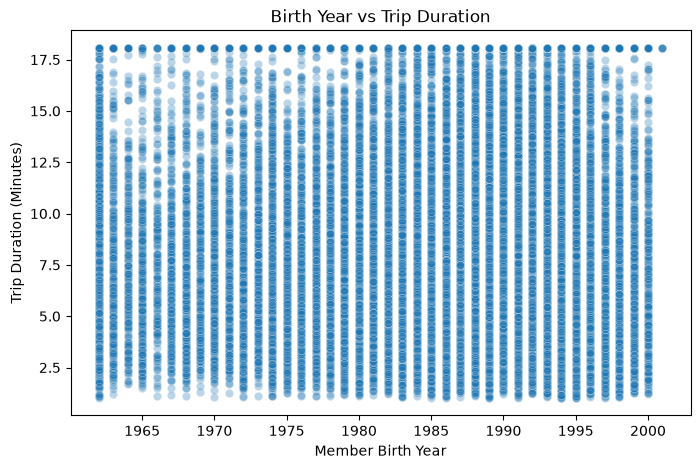

In [91]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="member_birth_year",
    y="duration_min",
    alpha=0.3
)

plt.title("Birth Year vs Trip Duration")
plt.xlabel("Member Birth Year")
plt.ylabel("Trip Duration (Minutes)")

plt.show()

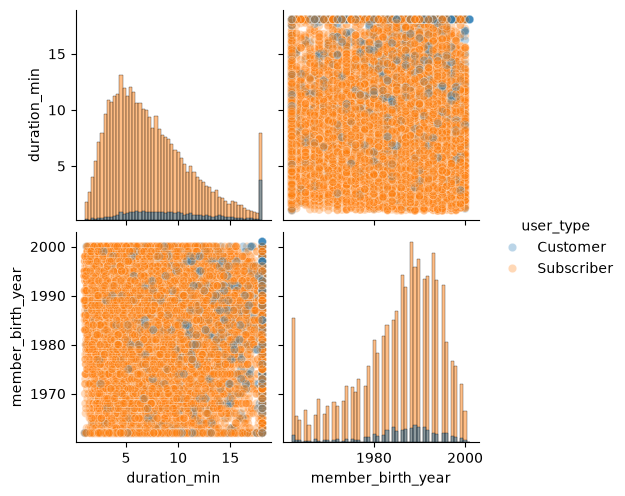

In [92]:
num_cols = ["duration_min", "member_birth_year"]

sns.pairplot(
    data=df,
    vars=num_cols,
    hue="user_type",
    diag_kind="hist",
    plot_kws={"alpha": 0.3}
)

plt.show()

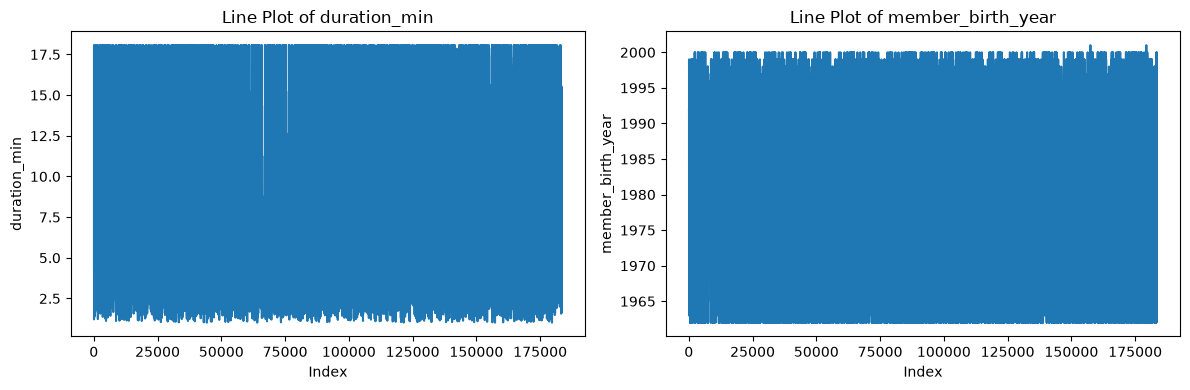

In [93]:
num_cols = ["duration_min", "member_birth_year"]

plt.figure(figsize=(12, 4))

for i, col in enumerate(num_cols):
    plt.subplot(1, len(num_cols), i + 1)

    sns.lineplot(data=df, x=df.index, y=col)

    plt.title(f"Line Plot of {col}")
    plt.xlabel("Index")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

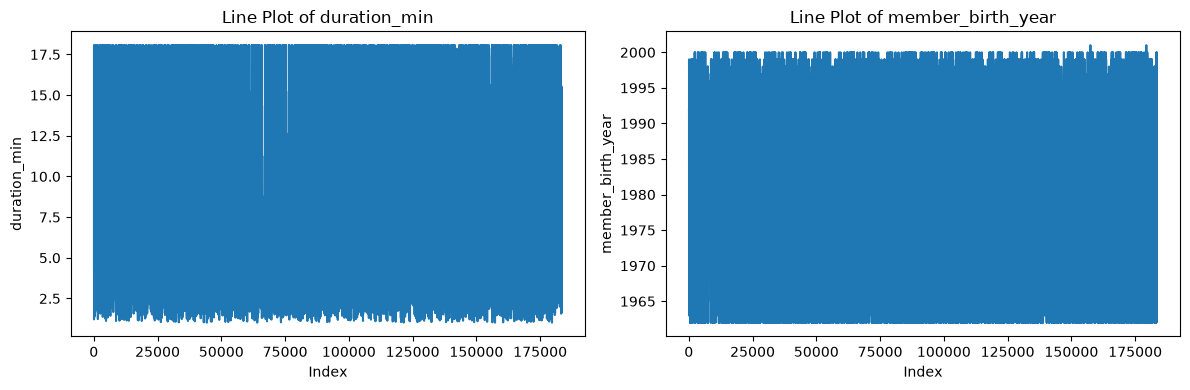

 Col Numerical and categorical

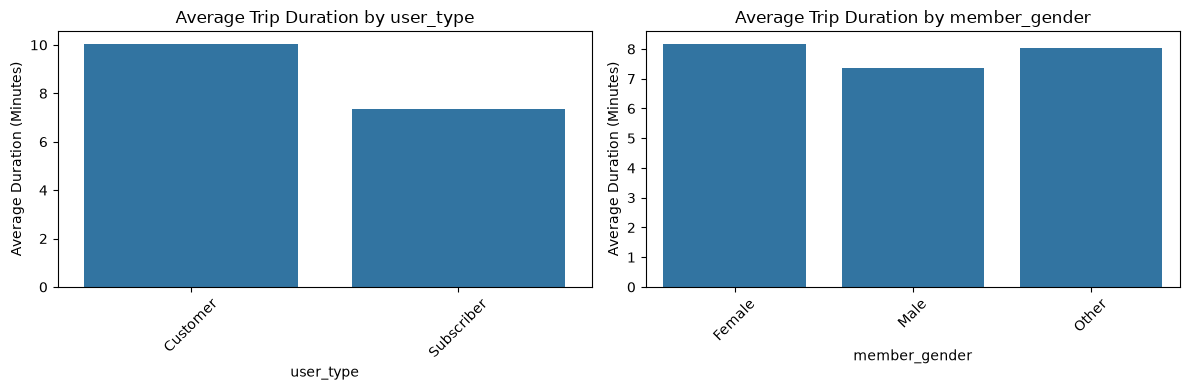

In [95]:
cat_cols = ["user_type", "member_gender"]

plt.figure(figsize=(12, 4))

for i, col in enumerate(cat_cols):
    plt.subplot(1, len(cat_cols), i + 1)

    sns.barplot(data=df, x=col, y="duration_min", errorbar=None)

    plt.title(f"Average Trip Duration by {col}")
    plt.xlabel(col)
    plt.ylabel("Average Duration (Minutes)")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

 Col Numerical and categorical

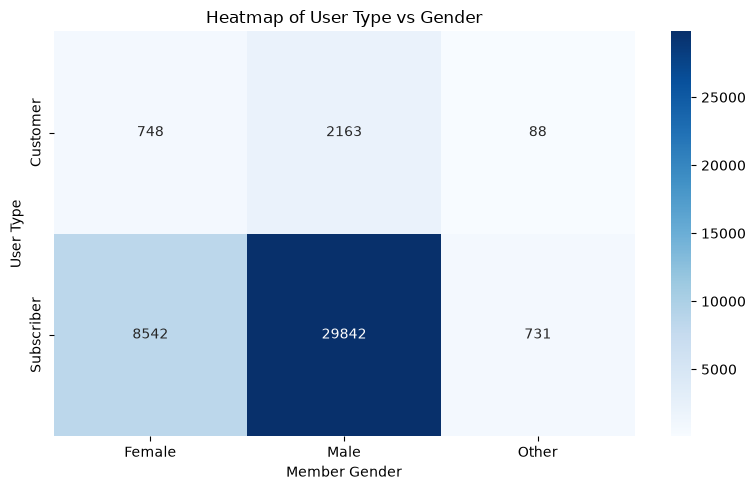

In [96]:
cat_cols = ["user_type", "member_gender"]

cross_tab = pd.crosstab(
    df[cat_cols[0]],
    df[cat_cols[1]]
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    cross_tab,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Heatmap of User Type vs Gender")
plt.xlabel("Member Gender")
plt.ylabel("User Type")

plt.tight_layout()
plt.show()